# 02. Моделирование: предсказание CaO по химическому составу

**Цель.** Оценить CaO (масс. %) по девяти оксидам-примесям и проверить, дают ли ML-модели
что-то сверх простых и физических baseline.

**План:**
1. сразу отложить тест **по группам** (источникам). Он не участвует ни в выборе моделей,
   ни в подборе гиперпараметров;
2. сравнить baseline (медиана, баланс масс, Ridge) и ML-модели (RandomForest, ExtraTrees,
   LightGBM, CatBoost, гибрид, стекинг) повторной групповой кросс-валидацией;
3. подобрать гиперпараметры (Optuna) на обучающей части;
4. проверить выбранную модель на отложенных источниках, разобрать ошибки и признаки (SHAP);
5. построить интервалы предсказания (conformal) и сохранить модель для `app/`.

**Метрики.** Основная — RMSE (сильнее штрафует грубые промахи), плюс MAE и R². Для сырья
важна точность в пределах ±1–2 % CaO, поэтому ещё считаем долю проб с ошибкой не больше 2 п.п.

### Мини-словарик

| Термин | Что значит |
|---|---|
| Baseline | Простой «конкурент». Если сложная модель его не обгоняет, она не нужна |
| Кросс-валидация (CV) | Данные делят на части: на одних учимся, на других проверяем, и так по кругу. Оценка получается без подглядывания |
| Группы (GroupKFold) | Такое разбиение, при котором пробы одной публикации целиком попадают либо в обучение, либо в проверку. Иначе модель «узнаёт» знакомый источник и качество завышается |
| Отложенная выборка (hold-out) | Данные, которых модель не видела до самого конца. На них один раз проверяем итог |
| Утечка | Когда в обучение попадает информация из проверочных данных. Результат выглядит лучше, чем будет в жизни |
| Ridge | Линейная регрессия со штрафом за слишком большие коэффициенты. Простая и устойчивая |
| Бустинг (LightGBM, CatBoost) | Много небольших деревьев, каждое исправляет ошибки предыдущих |
| Стекинг | Несколько разных моделей предсказывают отдельно, а ещё одна учится смешивать их ответы |
| RMSE / MAE / R² | RMSE и MAE — типичная ошибка в п.п. CaO (меньше — лучше). R² — доля объяснённого разброса: 1 — идеал, 0 — не лучше медианы |
| Optuna | Библиотека для автоматического подбора настроек модели |
| SHAP | Способ показать, какие признаки и насколько повлияли на ответ модели |
| Conformal-интервал | Диапазон вокруг предсказания, в который истинное значение должно попадать примерно в 90 % случаев |

## 0. Подготовка

Подключаем библиотеки и берём из `src/` готовые функции: загрузку данных, признаки, модели,
метрики. Саму логику держим в `src/`, там её проще тестировать, а здесь только эксперименты
и результаты.

In [1]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap
from scipy import stats
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

from src.features import (FEATURES, TARGET, RANDOM_STATE, OxideFeatures, load_data,
                          make_groups, split_xy, stoichiometric_cao)
from src.modeling import (GroupStack, ResidualBoost, StoichBaseline, build_stack,
                          catboost_model, default_models, forest_pipeline,
                          group_cv_predict, lgbm_model, linear_pipeline,
                          regression_metrics, repeated_group_cv, summarize,
                          tree_pipeline, with_groups)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)  # иначе Optuna печатает каждую попытку
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
FIG = "reports/figures/"

df = load_data()
X, y = split_xy(df)  # X — девять оксидов, y — CaO
groups = make_groups(df)  # группа каждой пробы: источник или его географический блок

## 1. Разбиение: отложенные источники

В тест уходит 20 % **групп** (публикаций и блоков), а не 20 % случайных строк. Так мы
имитируем реальный случай: модель применяют на новом карьере или в новой лаборатории,
которых в обучении не было.

In [2]:
# GroupShuffleSplit случайно выбирает целые группы в тест
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(splitter.split(X, y, groups))
X_tr, y_tr, g_tr = X.iloc[tr_idx], y.iloc[tr_idx], groups.iloc[tr_idx]
X_te, y_te, g_te = X.iloc[te_idx], y.iloc[te_idx], groups.iloc[te_idx]
assert set(g_tr) & set(g_te) == set()  # ни одной общей группы у train и test
print(f"train: {len(X_tr)} проб, {g_tr.nunique()} групп | test: {len(X_te)} проб, {g_te.nunique()} групп")
print(f"CaO train: {y_tr.mean():.1f}±{y_tr.std():.1f} | test: {y_te.mean():.1f}±{y_te.std():.1f}")

train: 2763 проб, 76 групп | test: 445 проб, 19 групп
CaO train: 38.5±12.3 | test: 29.7±16.8


## 2. Сравнение моделей: повторная групповая кросс-валидация

5 фолдов × 3 разных разбиения (`GroupKFold` с перемешиванием групп), и всё это только на
обучающей части. Импутация и масштабирование внутри пайплайнов учатся лишь на train-фолде,
так что утечки нет.

Сравниваем:
* **Median** — наивный baseline;
* **Stoichiometry** — физическая формула, без обучения;
* **Ridge** на 9 оксидах и на расширенных признаках;
* **RandomForest / ExtraTrees / LightGBM / CatBoost**;
* **Stoich + LGBM (остатки)** — гибрид: формула плюс бустинг, который учится на её ошибках;
* **Stack** — Ridge + LightGBM + CatBoost + ExtraTrees; поверх них неотрицательная
  линейная регрессия на out-of-fold предсказаниях.

In [3]:
# Бустинг для гибрида делаем маленьким и сильно регуляризованным: ему надо только слегка
# поправить формулу, а не заменить её
def lgbm_residual():
    return tree_pipeline(lgbm_model(RANDOM_STATE, n_estimators=300, num_leaves=8,
                                    min_child_samples=30, reg_lambda=5))

models = default_models()  # название -> функция, создающая свежую модель (см. src/modeling.py)
models["Stoich + LGBM (остатки)"] = lambda: ResidualBoost(StoichBaseline(), lgbm_residual())
models["Stack"] = lambda: build_stack()

# Самый долгий шаг: 5 фолдов x 3 повтора на каждую модель.
# cv_table — метрики каждого запуска, oofs — предсказания для каждой пробы от модели, которая её не видела
cv_table, oofs = repeated_group_cv(models, X_tr, y_tr, g_tr, seeds=(0, 1, 2), n_splits=5)
summary = summarize(cv_table)
summary.sort_values("RMSE_mean")

,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
model,,,,,,
Stack,3.206,0.048,1.828,0.024,0.933,0.002
ExtraTrees,3.306,0.015,1.861,0.016,0.928,0.001
Ridge (9 оксидов),3.322,0.016,2.037,0.018,0.928,0.001
Ridge (+признаки),3.324,0.017,2.063,0.016,0.927,0.001
CatBoost,3.333,0.025,1.942,0.024,0.927,0.001
RandomForest,3.384,0.056,1.939,0.029,0.925,0.002
LightGBM,3.390,0.013,2.029,0.020,0.925,0.001
Stoich + LGBM (остатки),3.466,0.001,2.012,0.019,0.921,0.000
Stoichiometry,3.704,0.000,2.050,0.000,0.910,0.000


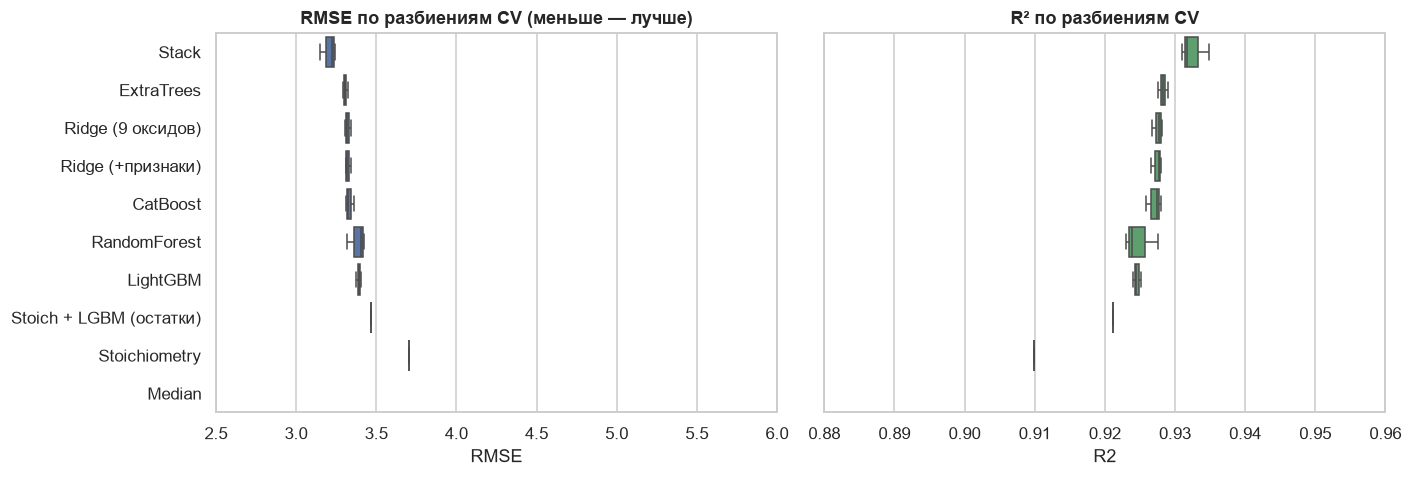

In [4]:
# По 15 запусков на модель. Чем левее и уже ящик RMSE, тем лучше и стабильнее модель
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = summary.sort_values("RMSE_mean").index
sns.boxplot(data=cv_table, y="model", x="RMSE", order=order, ax=axes[0], color="#4C72B0")
axes[0].set(title="RMSE по разбиениям CV (меньше — лучше)", ylabel="", xlim=(2.5, 6))
sns.boxplot(data=cv_table, y="model", x="R2", order=order, ax=axes[1], color="#55A868")
axes[1].set(title="R² по разбиениям CV", ylabel="", xlim=(0.88, 0.96), yticklabels=[])
plt.tight_layout(); plt.savefig(FIG + "cv_models.png", bbox_inches="tight"); plt.show()

**Промежуточные выводы.**
* Медиана бесполезна (R² ≈ 0): наивно задача не решается.
* Формула баланса масс — сильный baseline (R² ≈ 0.91), и Ridge на 9 оксидах её уже
  обгоняет. Связь почти линейная, это закон сохранения массы.
* Одиночные леса и бустинги примерно на уровне Ridge (RMSE 3.3–3.4), заметно лучше он
  не становится: нелинейности в данных мало.
* Расширенные признаки Ridge почти ничего не дают (3.324 против 3.322): линейная модель и
  так «видит» сумму оксидов.
* Гибрид «формула + бустинг» оказался хуже Ridge, поправки бустинга здесь только мешают.
* Лучший результат в CV у **стекинга**, который смешивает линейную и нелинейные модели.
  Выигрыш небольшой, значимость проверим ниже.

### Значимо ли улучшение?

Сравниваем стекинг с baseline по абсолютным ошибкам (OOF-предсказания одного разбиения):
критерий Уилкоксона для парных выборок плюс бутстрэп **по группам** для разницы RMSE.
Пробы одного источника зависимы, поэтому ресэмплим не строки, а группы.

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
uniq = g_tr.unique()
# для каждой группы запоминаем номера её строк, так собирать выборки для бутстрэпа быстрее
idx_by_group = {g: np.where(g_tr.to_numpy() == g)[0] for g in uniq}


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def group_bootstrap_diff(pred_a, pred_b, n_boot=1000):
    """Разница RMSE (b - a) с 95 % доверительным интервалом; >0 — модель a лучше."""
    # Много раз выбираем группы с возвращением, каждый раз считаем разницу RMSE.
    # Разброс этих разностей и есть доверительный интервал.
    diffs = []
    for _ in range(n_boot):
        sel = np.concatenate([idx_by_group[g] for g in rng.choice(uniq, len(uniq))])
        diffs.append(rmse(y_tr.to_numpy()[sel], pred_b[sel]) - rmse(y_tr.to_numpy()[sel], pred_a[sel]))
    return np.mean(diffs), np.percentile(diffs, [2.5, 97.5])


rows = []
for base in ["Median", "Stoichiometry", "Ridge (9 оксидов)"]:
    # Уилкоксон: ошибки стекинга систематически меньше ошибок baseline?
    w, p = stats.wilcoxon(np.abs(y_tr - oofs["Stack"]), np.abs(y_tr - oofs[base]))
    m, ci = group_bootstrap_diff(oofs["Stack"], oofs[base])
    rows.append({"baseline": base, "ΔRMSE (baseline − Stack)": round(m, 3),
                 "95% ДИ": f"[{ci[0]:.2f}; {ci[1]:.2f}]", "Wilcoxon p": f"{p:.1e}"})
pd.DataFrame(rows)

,baseline,ΔRMSE (baseline − Stack),95% ДИ,Wilcoxon p
0,Median,9.634,[7.44; 11.82],0.0e+00
1,Stoichiometry,0.509,[0.02; 1.06],3.1e-08
2,Ridge (9 оксидов),0.110,[-0.11; 0.39],8.4e-23


**Вывод.** Над медианой стекинг лучше уверенно, над физической формулой — на грани
значимости (ДИ [0.02; 1.06] едва не доходит до нуля). Против Ridge выигрыш маленький
(около 0.1 п.п. RMSE), а бутстрэп-интервал [−0.11; 0.39] включает 0. Тест Уилкоксона при
этом даёт крошечное p, но он не учитывает зависимость проб внутри источника, поэтому
доверяем бутстрэпу. Честный вывод: стекинг не хуже Ridge, но статистически значимо
превосходить его мы не можем.

## 3. Подбор гиперпараметров (Optuna)

Подбираем настройки LightGBM на обучающей части. Целевая функция — RMSE групповой
4-фолдовой CV, тестовые источники не используются.

In [6]:
Xg_tr = with_groups(X_tr, g_tr)  # метку группы кладём в индекс, его используют стекинг и GroupKFold


def objective(trial: optuna.Trial) -> float:
    """Одна попытка Optuna: берём настройки, считаем групповую CV, возвращаем RMSE."""
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 150, 700),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 31),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 60),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
    )
    errs = []
    for tr, va in GroupKFold(n_splits=4).split(Xg_tr, groups=Xg_tr.index):
        m = tree_pipeline(lgbm_model(RANDOM_STATE, **params)).fit(Xg_tr.iloc[tr], y_tr.iloc[tr])
        errs.append(rmse(y_tr.iloc[va].to_numpy(), m.predict(Xg_tr.iloc[va])))
    return float(np.mean(errs))


# minimize — ищем настройки с наименьшей ошибкой; seed нужен, чтобы результат повторялся
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40)
best_params = study.best_params
print("лучший CV-RMSE:", round(study.best_value, 3))
print(best_params)

лучший CV-RMSE: 3.183
{'n_estimators': 558, 'learning_rate': 0.013769846721169002, 'num_leaves': 26, 'min_child_samples': 7, 'reg_lambda': 0.03242216506823949, 'colsample_bytree': 0.523217242650689}


## 4. Оценка на отложенных источниках

Все модели заново обучаем на всей обучающей части и один раз проверяем на тесте.

In [7]:
final_models = {
    "Median": models["Median"],
    "Stoichiometry": models["Stoichiometry"],
    "Ridge (9 оксидов)": models["Ridge (9 оксидов)"],
    "LightGBM": models["LightGBM"],
    "CatBoost": models["CatBoost"],
    "Stack": lambda: build_stack(),
    "Stack (tuned LGBM)": lambda: build_stack(lgbm_params=best_params),
}
Xg_te = with_groups(X_te, g_te)
test_pred, rows = {}, []
for name, factory in final_models.items():
    model = factory().fit(Xg_tr, y_tr)
    test_pred[name] = model.predict(Xg_te)
    m = regression_metrics(y_te, test_pred[name])
    # доля проб с ошибкой до 2 п.п. — показатель, понятный технологам
    m["в пределах ±2 п.п., %"] = 100 * float(np.mean(np.abs(y_te - test_pred[name]) <= 2))
    rows.append({"model": name, **m})
test_table = pd.DataFrame(rows).set_index("model").round(3)
test_table

,RMSE,MAE,R2,"в пределах ±2 п.п., %"
model,,,,
Median,19.796,16.026,-0.398,7.865
Stoichiometry,3.712,2.263,0.951,66.517
Ridge (9 оксидов),3.705,2.148,0.951,71.461
LightGBM,4.606,2.851,0.924,60.449
CatBoost,4.775,2.975,0.919,59.326
Stack,3.863,2.386,0.947,66.517
Stack (tuned LGBM),3.863,2.386,0.947,66.517


### Какую модель берём для `app/`

Выбираем по **кросс-валидации на обучающей части**, а не по тесту. Если выбирать
победителя по тесту, он перестаёт быть независимым: выбор уже подогнан под него, и
качество получается завышенным. Поэтому выбор делаем по CV (раздел 2), а тест остаётся
честной проверкой уже выбранной модели.

Выбрана по CV на обучающей части: Stack
                   RMSE_mean  RMSE_std
model                                 
Ridge (9 оксидов)      3.322     0.016
LightGBM               3.390     0.013
CatBoost               3.333     0.025
Stack                  3.206     0.048

Её же качество на отложенных источниках:
RMSE                      3.863
MAE                       2.386
R2                        0.947
в пределах ±2 п.п., %    66.517


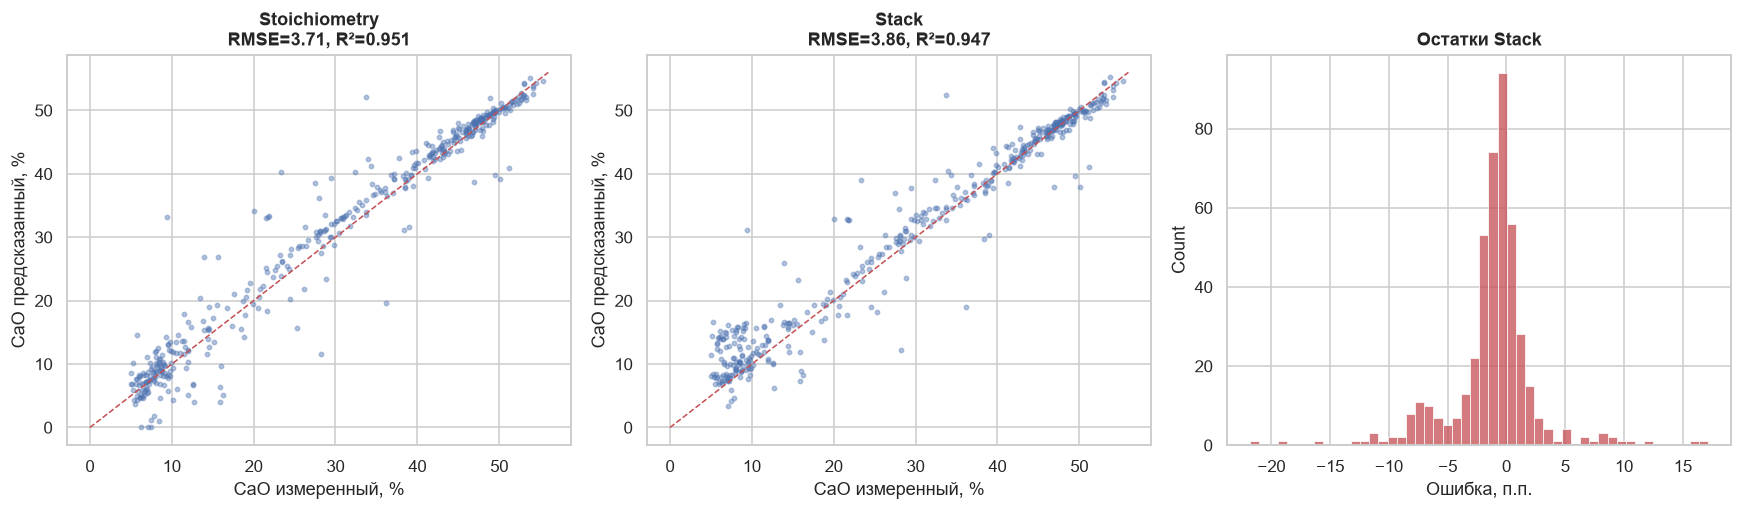

In [8]:
# среди настоящих ML-моделей (baseline не считаем) берём с лучшим CV-RMSE
candidates = ["Ridge (9 оксидов)", "LightGBM", "CatBoost", "Stack"]
best_name = summary.loc[candidates, "RMSE_mean"].idxmin()
print("Выбрана по CV на обучающей части:", best_name)
print(summary.loc[candidates, ["RMSE_mean", "RMSE_std"]].to_string())
print("\nЕё же качество на отложенных источниках:")
print(test_table.loc[best_name].to_string())

# слева формула, посередине выбранная модель (чем ближе точки к красной линии, тем лучше),
# справа распределение ошибок: хорошо, когда оно узкое и центрировано на нуле
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, name in zip(axes[:2], ["Stoichiometry", best_name]):
    ax.scatter(y_te, test_pred[name], s=8, alpha=.4)
    ax.plot([0, 56], [0, 56], "r--", lw=1)
    r = regression_metrics(y_te, test_pred[name])
    ax.set(title=f"{name}\nRMSE={r['RMSE']:.2f}, R²={r['R2']:.3f}", xlabel="CaO измеренный, %",
           ylabel="CaO предсказанный, %")
res = y_te.to_numpy() - test_pred[best_name]  # измеренное минус предсказанное
sns.histplot(res, bins=50, ax=axes[2], color="#C44E52")
axes[2].set(title=f"Остатки {best_name}", xlabel="Ошибка, п.п.")
plt.tight_layout(); plt.savefig(FIG + "test_results.png", bbox_inches="tight"); plt.show()

## 5. Анализ ошибок

Средняя ошибка скрывает проблемные места. Посмотрим, где модель ошибается сильнее: при
каком CaO, при каком числе пропусков, у какого класса породы. Для производства важно
знать, когда ей нельзя доверять.

In [9]:
err = pd.DataFrame({"y": y_te.to_numpy(), "pred": test_pred[best_name],
                    "rock_class": df.loc[X_te.index, "rock_class"].to_numpy(),
                    "n_missing": X_te.isna().sum(axis=1).to_numpy(), "group": g_te.to_numpy()})
err["abs_err"] = (err.y - err.pred).abs()
err["cao_bin"] = pd.cut(err.y, [0, 20, 30, 40, 50, 57])  # диапазоны CaO
print("По диапазону CaO:")
print(err.groupby("cao_bin", observed=True).abs_err.agg(["count", "mean"]).round(2).to_string())
print("\nПо числу пропущенных оксидов:")
print(err.groupby("n_missing").abs_err.agg(["count", "mean"]).round(2).to_string())
print("\nПо классу породы (на тесте):")
print(err.groupby("rock_class").abs_err.agg(["count", "mean"]).round(2).to_string())

По диапазону CaO:
          count  mean
cao_bin              
(0, 20]     158  3.42
(20, 30]     55  3.58
(30, 40]     57  2.47
(40, 50]    138  0.90
(50, 57]     37  1.58

По числу пропущенных оксидов:
           count  mean
n_missing             
0            366  2.29
1             62  2.94
2             12  2.78
3              3  2.49
4              1  0.23
5              1  0.56

По классу породы (на тесте):
                  count  mean
rock_class                   
calcareous_other    278  2.91
limestone           162  1.40
marl                  5  5.24


**Вывод.** Ошибка больше там, где CaO ниже (мергели, глинистые и доломитизированные
породы): в таких составах часть массы уходит в воду, сульфаты и органику, а этих
признаков у нас нет. В чистых известняках (CaO 40–50 %) ошибка самая маленькая. Это
согласуется с физикой и с выводами EDA.

### Мергель и мел

На тесте мергелей и мела почти нет, поэтому смотрим **out-of-fold** предсказания
групповой CV на всей обучающей части.

In [10]:
cls = df.loc[X_tr.index, "rock_class"].to_numpy()  # класс породы для каждой обучающей пробы
rows = []
for c in ["limestone", "calcareous_other", "marl", "chalk"]:
    mask = cls == c
    for name in ["Stoichiometry", "Stack"]:
        rows.append({"класс": c, "n": int(mask.sum()), "модель": name,
                     **{k: round(v, 2) for k, v in regression_metrics(y_tr[mask], oofs[name][mask]).items()}})
pd.DataFrame(rows)

,класс,n,модель,RMSE,MAE,R2
0,limestone,1799,Stoichiometry,3.56,2.11,0.92
1,limestone,1799,Stack,2.66,1.63,0.95
2,calcareous_other,940,Stoichiometry,3.98,1.92,0.89
3,calcareous_other,940,Stack,4.11,2.15,0.89
4,marl,20,Stoichiometry,2.82,2.25,0.96
5,marl,20,Stack,2.43,2.01,0.97
6,chalk,4,Stoichiometry,3.10,2.64,0.93
7,chalk,4,Stack,1.38,1.20,0.99


**Вывод.** На мергеле и меле MAE примерно как на известняках, но выборка крошечная
(25 и 4 пробы на всю базу), так что это скорее ориентир, чем доказательство. Чтобы
использовать модель на конкретном карьере, её надо проверить на местных анализах или
дообучить.

## 6. Интерпретация: SHAP

SHAP показывает вклад каждого признака (в п.п. CaO) в ответ модели для каждой пробы. Нам
нужно убедиться, что модель опирается на осмысленные признаки, а не на случайные
артефакты. Строим на LightGBM: он быстро считается и хорошо показывает общую картину.

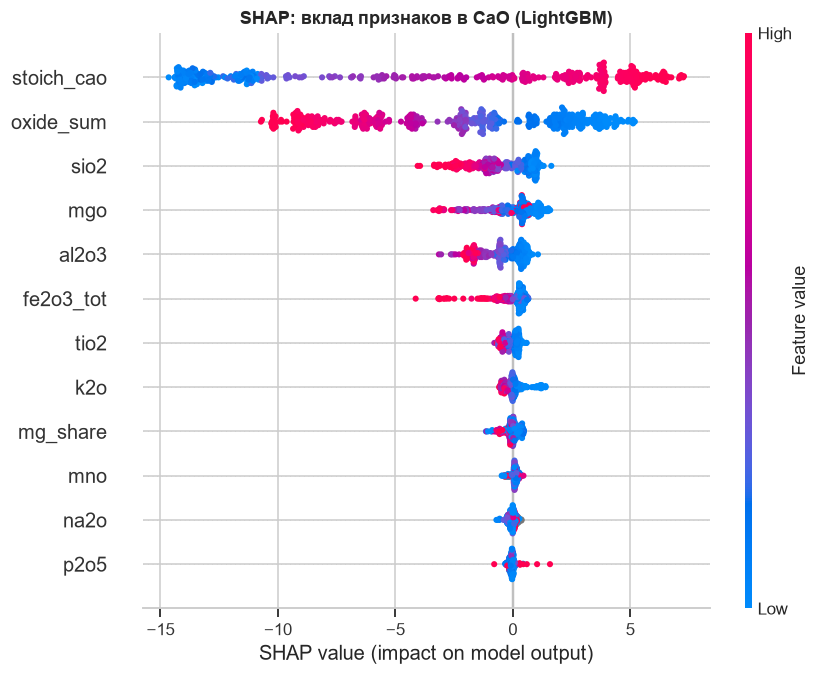

stoich_cao    6.98
oxide_sum     4.28
sio2          1.09
mgo           0.82
al2o3         0.79
fe2o3_tot     0.46
tio2          0.26
k2o           0.24


In [11]:
lgb_pipe = tree_pipeline(lgbm_model(RANDOM_STATE, **best_params)).fit(Xg_tr, y_tr)
feat = lgb_pipe[0].transform(X_te)  # признаки в том виде, в каком их видит модель (вместе с производными)
explainer = shap.TreeExplainer(lgb_pipe[-1])
sv = explainer.shap_values(feat)
plt.figure()
shap.summary_plot(sv, feat, show=False, max_display=12)
plt.title("SHAP: вклад признаков в CaO (LightGBM)")
plt.tight_layout(); plt.savefig(FIG + "shap_summary.png", bbox_inches="tight"); plt.show()
# средний по модулю вклад — общий рейтинг важности
imp = pd.Series(np.abs(sv).mean(axis=0), index=feat.columns).sort_values(ascending=False)
print(imp.round(2).head(8).to_string())

**Вывод.** Главные признаки — `stoich_cao` и `oxide_sum` (баланс масс), затем SiO₂ и MgO:
много SiO₂ снижает CaO, MgO отвечает за доломитовую часть. Модель опирается на
физически осмысленные переменные, метки породы в признаках нет.

## 7. Интервалы предсказания (split conformal)

Для производства важна не только оценка, но и её неопределённость. Берём 90-й
перцентиль абсолютных ошибок групповой CV на обучающей части как полуширину интервала и
проверяем, как часто он накрывает истинное значение на отложенных источниках.

In [12]:
# честные предсказания выбранной модели на обучающей части (каждую пробу предсказывает модель, не видевшая её группу)
oof_best = group_cv_predict(final_models[best_name], X_tr, y_tr, g_tr, n_splits=5, seed=7)
# в 90 % случаев ошибка была не больше этого числа, оно и есть полуширина интервала
q90 = float(np.quantile(np.abs(y_tr.to_numpy() - oof_best), 0.90))
pred_te = test_pred[best_name]
# покрытие: доля тестовых проб, у которых истинное значение попало в интервал
covered = np.abs(y_te.to_numpy() - pred_te) <= q90
print(f"Полуширина 90% интервала: ±{q90:.2f} п.п.; покрытие на тесте: {covered.mean():.1%}")

Полуширина 90% интервала: ±4.31 п.п.; покрытие на тесте: 82.7%


**Вывод.** Интервал ±4.31 п.п. подбирали так, чтобы он накрывал 90 % проб, но на новых
источниках покрытие ниже — 82.7 %. Ожидаемо: источники различаются (тест
Краскела–Уоллиса), и новые публикации оказываются «сложнее» тех, на которых интервал
калибровался. На практике его стоит считать немного оптимистичным (для нового источника
реально около 83 %). Ширина у интервала постоянная, это простое приближение. Дальше можно
сделать её зависимой от CaO и откалибровать на местных анализах конкретного карьера.

## 8. Сохранение модели

Финальную модель обучаем заново на **всех** данных (обучение + отложенные источники) и
сохраняем вместе с метаданными. Метрики в отчёт берём из проверки на отложенных
источниках выше: на них выбранная модель ещё не училась.

In [13]:
# учимся на всех 3208 пробах, чтобы использовать максимум данных
final = final_models[best_name]().fit(with_groups(X, groups), y)
# metadata.json — «паспорт» модели: какая она, на каких признаках, с каким качеством
meta = {
    "model": best_name, "features": FEATURES, "target": TARGET,
    "interval_halfwidth_90": round(q90, 3),
    "holdout_metrics": test_table.loc[best_name].round(4).to_dict(),
    "selected_by": "CV RMSE на обучающей части (тест не использовался для выбора)",
    "cv_metrics_train": summary.loc[best_name].to_dict(),
    "n_train_samples": int(len(X)),
    "note": "Обучено на глобальной базе карбонатных пород (США ~55%); на новом карьере проверить локально.",
}
# модель и паспорт лежат в одном файле, его читает app/predict.py
joblib.dump({"model": final, "meta": meta}, "models/cao_model.joblib", compress=3)
with open("models/metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
test_table.to_csv("reports/holdout_metrics.csv")
summary.to_csv("reports/cv_metrics.csv")
print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "model": "Stack",
  "features": [
    "sio2",
    "al2o3",
    "fe2o3_tot",
    "mgo",
    "k2o",
    "na2o",
    "tio2",
    "p2o5",
    "mno"
  ],
  "target": "cao",
  "interval_halfwidth_90": 4.31,
  "holdout_metrics": {
    "RMSE": 3.863,
    "MAE": 2.386,
    "R2": 0.947,
    "в пределах ±2 п.п., %": 66.517
  },
  "selected_by": "CV RMSE на обучающей части (тест не использовался для выбора)",
  "cv_metrics_train": {
    "RMSE_mean": 3.206,
    "RMSE_std": 0.048,
    "MAE_mean": 1.828,
    "MAE_std": 0.024,
    "R2_mean": 0.933,
    "R2_std": 0.002
  },
  "n_train_samples": 3208,
  "note": "Обучено на глобальной базе карбонатных пород (США ~55%); на новом карьере проверить локально."
}


## Итоги

* Задача — регрессия CaO по 9 оксидам без LOI. Валидация по источникам (`GroupKFold` и
  отложенные группы), поэтому пробы одной публикации не попадают одновременно в train и test.
* Итоговая модель выбрана по групповой CV на обучающей части, а не по тесту, так что
  качество на отложенных источниках — честная оценка для новых источников.
* Baseline два: медиана и формула баланса масс. Сильный линейный baseline — Ridge.
* Сравнили линейные модели, леса, бустинги, гибрид и стекинг. В групповой CV лучший —
  стекинг, а на отложенных источниках Ridge и формула не хуже ансамбля (см. таблицы выше).
* Прирост ML скромный: над формулой около 0.5 п.п. RMSE, над Ridge около 0.1 п.п., и
  против Ridge он статистически не значим. Задача почти линейна, простые модели здесь
  очень сильны, а ансамбль добавляет скорее устойчивость.
* Модель лежит в `models/cao_model.joblib`, к ней есть интервалы предсказания и CLI/API в `app/`.

**Ограничения:** данные неравномерны географически (США ~55 %), мергелей всего 25, мела 4,
неизвестны LOI, влажность и метод анализа. Для конкретного карьера нужна локальная
проверка или дообучение.